# هل تساعد معاينة الكتاب القارئ على اختيار ما يحفظه؟

## 0. بيانات المشروع

| البند | القيمة |
|---|---|
| المشروع | معاينة المحتوى في نتائج البحث عن الكتب |
| اسم الفريق | A&Y&F |
| أعضاء الفريق | 1. عبدالوهاب النصار، 2. يوسف المطيري، 3. فراس الناصر |
| المنتج | مكتبة كتب إلكترونية افتراضية تتيح البحث وحفظ الكتب في قائمة القراءة |
| المرحلة | اليوم الأول من مشروع التجارب واختبارات A/B والاستدلال السببي |

## 1. السؤال والفرضية

**القرار:** هل نعرض مقتطفًا قصيرًا من وصف الكتاب داخل بطاقة نتيجة البحث؟
**A:** تعرض البطاقة الغلاف والعنوان والمؤلف. **B:** تعرض العناصر نفسها مع مقتطف من الوصف لا يتجاوز سطرين. ترتيب الكتب والأزرار ثابت في النسختين.

**الفرضية:** إذا ظهر المقتطف في نتائج البحث، فستزيد نسبة المستخدمين الذين يحفظون كتابًا خلال 24 ساعة من أول بحث مؤهل، لأن المقتطف يساعدهم على تقدير ملاءمة الكتاب قبل فتح صفحته.

**ما الذي يغيّر رأينا؟** نقترح الإطلاق إذا ارتفع معدل الحفظ بمقدار نقطتين مئويتين على الأقل، وكان الحد الأدنى لفترة الثقة 95% لفرق B عن A أعلى من الصفر، وبقيت مقاييس الحماية ضمن الحدود أدناه. إذا لم تتحقق الشروط، نؤجل الإطلاق. هذه حدود قرار مقترحة قبل جمع البيانات.

## 2. تصميم التجربة

| البند | التعريف |
|---|---|
| الأهلية وبداية القياس | نُدخل المستخدم المسجّل عند أول بحث يعرض كتابًا واحدًا على الأقل له وصف، ونحدد أهليته قبل عرض النسخة. |
| وحدة العشوأة | حساب المستخدم. يبقى الحساب في النسخة نفسها عبر الزيارات والأجهزة. |
| نسبة التوزيع | 50% لكل نسخة باستخدام تجزئة ثابتة لمعرّف التجربة والحساب. |
| المقياس الرئيسي | عدد المستخدمين الموزّعين الذين حفظوا كتابًا من نتائج البحث خلال 24 ساعة ÷ جميع المستخدمين الموزّعين الذين اكتملت نافذتهم. يُحسب المستخدم مرة واحدة مهما تعددت عمليات الحفظ. |
| مقاييس ثانوية | نسبة المستخدمين الذين فتحوا صفحة كتاب من النتائج خلال 24 ساعة، ومتوسط عدد الكتب المختلفة المحفوظة لكل مستخدم موزّع خلال النافذة نفسها. |
| مقاييس الحماية | زمن عرض النتائج عند المئين 95: نسمح بزيادة حتى 150 مللي ثانية. معدل طلبات البحث الفاشلة: نسمح بزيادة حتى 0.2 نقطة مئوية. نقارن B مع A. |
| شرط SUTVA | قائمة القراءة خاصة بكل حساب. نثبّت ترتيب النتائج ونعطّل إعادة الترتيب المبنية على نشاط المشاركين حتى لا يغيّر حفظ مستخدم نتائج مستخدم آخر. |
| فحص الثقة قبل التحليل | نتحقق من ثبات التخصيص، ثم نفحص SRM على أعداد الحسابات الموزّعة مقابل 50/50. إذا كانت قيمة p أقل من 0.001 نراجع التوزيع والتسجيل قبل تفسير الأثر. |

خلية التحقق أدناه تستخدم معرّفات اصطناعية لفحص آلية التخصيص فقط. يبدأ المشروع هنا بتصميم التجربة، وتُحدَّد العينة والمدة في اليوم الثاني.

In [1]:
from hashlib import sha256

def assign_variant(user_id):
    key = f"book-search-preview-v1:{user_id}".encode("utf-8")
    bucket = int.from_bytes(sha256(key).digest()[:8], "big")
    return "B" if bucket < 2**63 else "A"

# معرّفات اختبار مستقلة عن بيانات القالب.
test_ids = [f"demo-{i}" for i in range(20)]
first_visit = {uid: assign_variant(uid) for uid in test_ids}
second_visit = {uid: assign_variant(uid) for uid in reversed(test_ids)}
assert first_visit == second_visit
assert set(first_visit.values()) == {"A", "B"}
print("نجح اختبار التخصيص: بقيت الحسابات العشرون في نسخها عند إعادة الزيارة.")

نجح اختبار التخصيص: بقيت الحسابات العشرون في نسخها عند إعادة الزيارة.


## 3. اليوم الثاني | حجم العينة ومدة تجربة معاينة الكتب

نحسب عدد **الحسابات** اللازمة لمقارنة نسبة من يحفظون كتابًا خلال 24 ساعة من أول بحث مؤهل. يظهر المقتطف للنسخة B، وتبقى النسخة A على التصميم الحالي.

| مدخل التخطيط | القيمة | أساس الاختيار |
|---|---:|---|
| معدل الحفظ في A | 18% | افتراض تخطيطي للمنتج الافتراضي؛ يُراجع من سجلّات ما قبل التجربة عند توفرها. |
| أصغر زيادة مطلوبة | نقطتان مئويتان، من 18% إلى 20% | حد الأثر العملي الذي حدده الفريق في اليوم الأول؛ يعادل زيادة نسبية 11.1%. |
| تدفّق المشاركين | 800 حساب مؤهل جديد يوميًا إجمالًا | افتراض تخطيطي؛ يُحسب الحساب مرة واحدة عند أول بحث مؤهل. |
| التوزيع | 50% لكل نسخة | نفس التخصيص الثابت على مستوى الحساب في اليوم الأول. |
| الدلالة والقوة | 5% لاختبار ثنائي الطرف، وقوة 80% | تُحسب العينة لاكتشاف فرق عن الصفر عندما يكون الأثر الحقيقي نقطتين. تبقى شروط الإطلاق ومقاييس الحماية كما حُدّدت في اليوم الأول. |

**قرار الفريق.** نعتمد **21 يومًا للتسجيل** تغطي ثلاث دورات أسبوعية كاملة، ثم ننتظر **24 ساعة** حتى تكتمل نافذة الحفظ لآخر مشارك. الحد الأدنى **6,036 حسابًا لكل نسخة**، ونتوقع **8,400** خلال الخطة. أسبوع واحد يوفّر نحو 2,800 حساب لكل نسخة، ويكشف فرقًا يقارب **2.88 نقطة**، أكبر من هدفنا. خلال المدة المخططة ينخفض هذا الرقم إلى **1.66 نقطة**. المدة مقبولة في هذا السيناريو؛ وإذا انخفض التدفق ولم نصل إلى الحد الأدنى في كل مجموعة، نمدّد التسجيل بأسابيع كاملة وفق أعداد المشاركين، دون استخدام نتائج الحفظ لاتخاذ قرار التمديد.

الحساب التالي يستخدم تقريب النسبتين ودالة أصغر أثر قابل للاكتشاف الواردين في التدريب. القيم أعلاه تخص التخطيط، ولا تمثّل نتائج تجربة منفّذة.

In [2]:
from math import ceil, sqrt
from statistics import NormalDist

CONFIG = {
    "baseline_save_rate": 0.18,
    "mde_abs": 0.02,
    "daily_eligible_accounts": 800,
    "treatment_share": 0.50,
    "alpha": 0.05,
    "power": 0.80,
    "follow_up_hours": 24,
}

p_a = CONFIG["baseline_save_rate"]
p_b = p_a + CONFIG["mde_abs"]
daily = CONFIG["daily_eligible_accounts"]
assert CONFIG["treatment_share"] == 0.5  # الصيغة لمجموعتين متساويتين
normal = NormalDist()
z_sum = normal.inv_cdf(1 - CONFIG["alpha"] / 2) + normal.inv_cdf(CONFIG["power"])
variance = p_a * (1 - p_a) + p_b * (1 - p_b)
n_min = ceil(z_sum**2 * variance / CONFIG["mde_abs"]**2)
days_min = ceil(2 * n_min / daily)
weeks = ceil(days_min / 7)
days = 7 * weeks

print(f"الحد الأدنى: {n_min:,} حسابًا لكل نسخة، أي {2 * n_min:,} إجمالًا.")
print(f"التسجيل: {days_min} يومًا قبل التقريب، و{days} يومًا ({weeks} أسابيع) بعده.")
for label, period in [("مدة الخطة", days), ("أسبوع واحد", 7)]:
    per_group = period * daily * CONFIG["treatment_share"]
    mde = z_sum * sqrt(2 * p_a * (1 - p_a) / per_group)
    print(f"{label}: {per_group:,.0f} حساب لكل نسخة، وأصغر أثر تقريبي {100 * mde:.2f} نقطة مئوية.")
print(f"موعد التحليل: بعد {days} يوم تسجيل و{CONFIG['follow_up_hours']} ساعة متابعة لآخر حساب.")

الحد الأدنى: 6,036 حسابًا لكل نسخة، أي 12,072 إجمالًا.
التسجيل: 16 يومًا قبل التقريب، و21 يومًا (3 أسابيع) بعده.
مدة الخطة: 8,400 حساب لكل نسخة، وأصغر أثر تقريبي 1.66 نقطة مئوية.
أسبوع واحد: 2,800 حساب لكل نسخة، وأصغر أثر تقريبي 2.88 نقطة مئوية.
موعد التحليل: بعد 21 يوم تسجيل و24 ساعة متابعة لآخر حساب.


## 4. اليوم الثالث | خطة التحليل قبل المحاكاة

نحلل الحسابات حسب النسخة المخصصة لها عند أول بحث مؤهل (ITT). ننتظر 21 يوم تسجيل واكتمال نافذة الـ24 ساعة لآخر حساب، ونتحقق من بلوغ 6,036 حسابًا في كل ذراع. إذا فشل فحص سلامة السجلات أو كان اختبار SRM مقابل 50/50 يعطي p < 0.001، نوقف تفسير النتائج.

- **الحفظ خلال 24 ساعة:** نقدّر فرق B−A بالنقاط المئوية وفترة ثقة 95% قبل التعديل وبعد CUPED. نستخدم عدد الكتب المحفوظة خلال الـ90 يومًا السابقة للتخصيص متغيرًا مساعدًا. التقدير المعدّل هو تقدير القرار.
- **المقاييس الثانوية:** فتح صفحة كتاب واحد على الأقل، وعدد الكتب المختلفة المحفوظة لكل حساب، بما يشمل الأصفار. نصحح قيم p للاختبارين بطريقة Benjamini–Hochberg عند 5%.
- **الحماية:** فرق المئين 95 لزمن عرض النتائج بين الطلبات الناجحة، وفرق نسبة الطلبات الفاشلة من جميع الطلبات المؤهلة. نعيد أخذ العينات على مستوى الحساب للحفاظ على ترابط طلباته. نعتبر الحماية محققة إذا كان الحد الأعلى لفترة الثقة 95% دون هامش الضرر (150 مللي ثانية و0.2 نقطة مئوية على الترتيب).
- **الحداثة والقرار:** نعرض الأثر حسب يوم دخول الحساب ونقارن الأسبوع الأول بالأسبوعين التاليين وصفيًا. نقترح الإطلاق في السيناريو إذا بلغ التقدير المعدّل نقطتين مئويتين على الأقل، وتجاوز الحد الأدنى لفترة ثقته الصفر، واجتازت التجربة فحوص الثقة والحماية. لا نوقف التجربة مبكرًا بناءً على الرسم اليومي.

## 5. إنشاء بيانات المكتبة الافتراضية

نولّد حسابات جديدة وطلبات بحث تابعة لها. نعيد استخدام تخصيص اليوم الأول وإعدادات اليوم الثاني. نفترض لأغراض التدريب زيادة قدرها نقطتان في احتمال الحفظ، وزيادة 30 مللي ثانية في زمن العرض، واحتمال فشل طلب 0.6% في النسختين. هذه مدخلات محاكاة؛ الأثر الذي سيقدّره التحليل يعتمد على العينة المتولدة.

In [3]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
size = days * CONFIG["daily_eligible_accounts"]
ids = [f"reader-{i}" for i in range(size)]
variant = np.array([assign_variant(uid) for uid in ids])
treated = variant == "B"
day = np.repeat(np.arange(1, days + 1), CONFIG["daily_eligible_accounts"])
# نشاط سابق ذو مستويين متساويي الاحتمال، ومتوسط خط أساس متوقع 18%.
active = rng.binomial(1, 0.5, size)
prior = rng.poisson(1 + 6 * active)
n_requests = rng.integers(1, 5, size)
owner = np.repeat(np.arange(size), n_requests)
failed = rng.random(len(owner)) < 0.006
latency = rng.lognormal(np.log(260), 0.35, len(owner)) + 30 * treated[owner]
can_view = np.bincount(owner, weights=~failed, minlength=size) > 0
save_prob = CONFIG["baseline_save_rate"] + 0.18 * (active - 0.5) + 0.02 * treated
saved = can_view & (rng.random(size) < save_prob)
books = saved * (1 + rng.poisson(0.35, size))
opened = saved | (can_view & (rng.random(size) < 0.36 + 0.12 * active))
data = pd.DataFrame(dict(account=ids, group=variant, day=day, prior=prior,
                         saved=saved.astype(int), books=books, opened=opened.astype(int)))
print(f"{len(data):,} accounts | {len(owner):,} search requests | {days} enrollment days")

16,800 accounts | 42,113 search requests | 21 enrollment days


In [4]:
# 6. فحوص الثقة: اكتمال 24 ساعة لكل حساب افتراض في المحاكاة.
# في المنتج نتحقق من مرور 24 ساعة بين أول بحث مؤهل واستخراج البيانات، ثم نفحص وقوع الحفظ داخل النافذة.
assert data.account.is_unique and not data.isna().any().any()
assert np.array_equal(data.group, [assign_variant(uid) for uid in data.account])
assert np.array_equal(data.saved, (data.books > 0).astype(int))
counts = data.group.value_counts().reindex(["A", "B"])
srm_p = stats.chisquare(counts, f_exp=[size / 2, size / 2]).pvalue
print(f"A={counts.A:,}, B={counts.B:,}, SRM p={srm_p:.4f}")
if srm_p < 0.001 or counts.min() < n_min:
    raise ValueError("Review allocation and sample size before interpreting effects.")

A=8,431, B=8,369, SRM p=0.6324


## 7. تحليل نتائج المحاكاة

الفرق في جميع الجداول هو B ناقص A. نعرض النسب وفروقها بالنقاط المئوية، وعدد الكتب بوحدة كتاب لكل حساب، والزمن بالمللي ثانية.

In [5]:
# 7.1 و7.2: الفرق وفترة الثقة، CUPED، وتصحيح المقاييس الثانوية
def compare(values, scale=1):
    a, b = (np.asarray(values)[variant == arm] * scale for arm in ["A", "B"])
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
    return pd.Series(dict(A=a.mean(), B=b.mean(), diff=diff, lo=diff-1.96*se,
                          hi=diff+1.96*se, SE=se, p=2*stats.norm.sf(abs(diff/se))))

theta = data.saved.cov(data.prior) / data.prior.var()
adjusted = data.saved - theta * (data.prior - data.prior.mean())
primary = pd.DataFrame({"Raw": compare(data.saved, 100),
                        "CUPED": compare(adjusted, 100)}).T
print(primary.round(4).to_string())
print(f"Variance reduction: {1-(primary.SE.CUPED/primary.SE.Raw)**2:.1%}")
secondary = pd.DataFrame({"Opened (%)": compare(data.opened, 100),
                          "Books/account": compare(data.books)}).T
secondary["p_BH"] = stats.false_discovery_control(secondary.p, method="bh")
secondary["significant_BH"] = secondary.p_BH < CONFIG["alpha"]
print(secondary.round(4).to_string())

             A        B    diff      lo      hi      SE    p
Raw    17.4594  20.7313  3.2719  2.0840  4.4598  0.6061  0.0
CUPED  17.4068  20.7842  3.3774  2.2146  4.5401  0.5932  0.0
Variance reduction: 4.2%
                     A        B    diff      lo      hi      SE       p    p_BH  significant_BH
Opened (%)     51.8325  52.9812  1.1487 -0.3617  2.6591  0.7706  0.1361  0.1361           False
Books/account   0.2353   0.2791  0.0438  0.0260  0.0616  0.0091  0.0000  0.0000            True


In [6]:
# 7.3: إعادة أخذ عينات الحسابات مع جميع طلباتها داخل كل ذراع
boot = np.random.default_rng(2027)
def guardrails(arm, draws=1000):
    accounts = np.flatnonzero(variant == arm)
    mask = variant[owner] == arm
    local_owner = np.searchsorted(accounts, owner[mask])
    failures = np.bincount(local_owner, weights=failed[mask], minlength=len(accounts))
    requests = n_requests[accounts]
    good = ~failed[mask]
    order = np.argsort(latency[mask][good])
    times = latency[mask][good][order]
    user = local_owner[good][order]

    def metrics(weights):
        ranks = weights[user].cumsum()
        p95 = times[np.searchsorted(ranks, np.ceil(0.95 * ranks[-1]))]
        error_pct = 100 * (weights @ failures) / (weights @ requests)
        return [p95, error_pct]

    observed = metrics(np.ones(len(accounts), dtype=int))
    samples = []
    for _ in range(draws):
        sampled = boot.integers(len(accounts), size=len(accounts))
        samples.append(metrics(np.bincount(sampled, minlength=len(accounts))))
    return np.array(observed), np.array(samples)

ga, sa = guardrails("A")
gb, sb = guardrails("B")
low, high = np.quantile(sb-sa, [0.025, 0.975], axis=0)
guards = pd.DataFrame(dict(A=ga, B=gb, diff=gb-ga, lo=low, hi=high,
                           limit=[150, 0.2]), index=["p95 latency (ms)", "Failed requests (%)"])
guards["pass"] = guards.hi < guards.limit
print(guards.round(3).to_string())

                           A        B   diff      lo      hi  limit  pass
p95 latency (ms)     466.317  489.026  22.71  15.782  29.152  150.0  True
Failed requests (%)    0.584    0.574  -0.01  -0.142   0.136    0.2  True


Save-rate difference by enrollment week (percentage points):
day
1    2.70
2    2.93
3    4.18


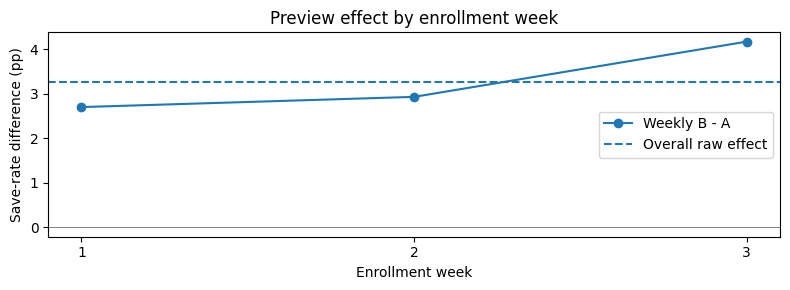

Simulation decision: Launch


In [7]:
# 7.4 أثر المقتطف حسب أسبوع التسجيل
week = (data.day - 1) // 7 + 1
weekly = data.groupby([week, "group"]).saved.mean().unstack()
print("Save-rate difference by enrollment week (percentage points):")
print((100 * (weekly.B - weekly.A)).round(2).to_string())
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(weekly.index, 100 * (weekly.B - weekly.A), marker="o", label="Weekly B - A")
ax.axhline(primary.loc["Raw", "diff"], ls="--", label="Overall raw effect")
ax.axhline(0, color="gray", lw=0.7)
ax.set(xlabel="Enrollment week", ylabel="Save-rate difference (pp)", xticks=[1, 2, 3])
ax.set_title("Preview effect by enrollment week")
ax.legend()
fig.tight_layout()
plt.show()
effect = primary.loc["CUPED"]
launch = effect["diff"] >= 100*CONFIG["mde_abs"] and effect.lo > 0 and guards["pass"].all()
print("Simulation decision:", "Launch" if launch else "Hold rollout")

### قراءة النتائج

اجتازت العينة فحص التوزيع (A = 8,431، B = 8,369، وقيمة p = 0.6324). ارتفع الحفظ المرصود من 17.46% إلى 20.73%. بعد CUPED بلغ الفرق **+3.38 نقطة مئوية** وفترة الثقة 95% **[+2.21، +4.54]**، وانخفض التباين 4.2%.

بعد تصحيح BH ارتفع متوسط عدد الكتب المحفوظة بمقدار 0.044 كتاب لكل حساب؛ أما فتح صفحة كتاب فبقيت فترة ثقته تشمل الصفر. ارتفع المئين 95 لزمن العرض 22.7 مللي ثانية (الحد الأعلى 29.2، مقابل هامش 150). بلغ الحد الأعلى لزيادة معدل الفشل 0.136 نقطة، دون هامش 0.2 نقطة. كان فرق الحفظ خلال أول 24 ساعة موجبًا في دفعات التسجيل الأسبوعية الثلاث (+2.70 ثم +2.93 ثم +4.18 نقطة). يعرض الرسم أثر المقتطف حسب أسبوع التسجيل. معرفة استمرار الأثر لدى القارئ نفسه تتطلب متابعته مدة أطول.

**قرار السيناريو:** استوفى المقتطف شروط الإطلاق في العينة الاصطناعية. إثبات الأثر على قرّاء حقيقيين يتطلب تنفيذ التجربة على المنتج. القسم 8 (الفروق في الفروق) اختياري لحالة يتعذر فيها التوزيع العشوائي؛ تجربة المكتبة تتيح التخصيص على مستوى الحساب.

## 9. تقرير التجربة والتوصية | اليوم الرابع

**قرار فريق A&Y&F:** توصي نتائج المحاكاة باختبار المقتطف على قرّاء حقيقيين تمهيدًا للإطلاق. داخل السيناريو اجتازت النسخة B شروط الإطلاق المحددة مسبقًا.

| البند | النتيجة |
|---|---|
| السؤال | هل يزيد عرض مقتطف من سطرين في نتائج البحث نسبة الحسابات التي تحفظ كتابًا خلال 24 ساعة؟ |
| التصميم | 16,800 حساب اصطناعي، 21 يوم تسجيل، تخصيص ثابت 50/50. بلغ عدد الحسابات في A وB على الترتيب 8,431 و8,369؛ فحص SRM أعطى p = 0.6324. |
| الحفظ المرصود | 17.46% في A و20.73% في B. الفرق الخام +3.27 نقطة مئوية (95%: +2.08 إلى +4.46). |
| تقدير القرار | بعد CUPED زاد الحفظ 3.38 نقطة مئوية (95%: +2.21 إلى +4.54). تجاوز التقدير هدف النقطتين وكان حد الثقة الأدنى موجبًا. |
| زمن العرض | زاد المئين 95 بمقدار 22.7 مللي ثانية (95%: 15.8 إلى 29.2)، ضمن هامش 150 مللي ثانية. |
| فشل الطلبات | الفرق −0.010 نقطة مئوية (95%: −0.142 إلى +0.136)، ضمن هامش +0.2 نقطة. |
| النتائج الثانوية | ارتفع متوسط الكتب المحفوظة 0.044 كتاب لكل حساب؛ ظل أثر فتح صفحة الكتاب غير حاسم بعد تصحيح BH. |
| الأثر السنوي المشروط | عند 800 حساب مؤهل جديد يوميًا و365 يومًا، ينتج عن تعميم المقتطف نحو 9,862 حسابًا إضافيًا يحفظ كتابًا سنويًا (نحو 6,467–13,257)، بافتراض ثبات التدفق والأثر. |

**الخطوة التالية:** نُسجّل توقيت أول بحث والحفظ واستخراج البيانات، ونختبر النسخة على عينة فعلية وفق قاعدة القرار السابقة.
**القيود:** البيانات اصطناعية واكتمال المتابعة مفترض. الفروق الأسبوعية تصف دفعات دخول مختلفة. يتطلب تقدير استمرار المنفعة متابعة الحسابات نفسها بعد اليوم الأول.

## 10. ملفات العرض والتسليم

[مستودع الفريق والتقرير وعرض العشر دقائق](https://github.com/Abdulwahab-Alnassar/experiments-ab-testing-and-causal-inference)